# Experimento complementar — ablação e estabilidade do detector de mixers
**Disciplina:** Segurança em Redes de Computadores | **Grupo:** reprodução do artigo de Leale & Sendin (SBSeg 2025)

**Propósito:** testar a contribuição das quatro características sem sobrescrever os resultados anteriores. Este notebook utiliza `features_treino.parquet` e `features_teste_20201029.parquet` já produzidos pelos notebooks 03/04. **Não baixa datasets brutos.** Se os arquivos processados não estiverem no atalho do Drive, esta versão recupera diretamente os dois arquivos Parquet pelo ID compartilhado (aproximadamente 9 MB e 13 KB).

**Cuidado:** as 23 janelas positivas vêm de um único contrato Tornado Cash (10 ETH). A validação cruzada entre dias pode superestimar a generalização. Os demais candidatos no teste não têm necessariamente rótulo confirmado. Consequentemente, as colunas `outros_sinalizados` não são automaticamente falsos positivos.

## 1. Montagem do Drive e carregamento dos dados

In [1]:
# Esta célula localiza os arquivos no Drive e, se o atalho estiver incompleto,
# baixa diretamente os dois Parquets pequenos usando sua conta Google.
from google.colab import drive
from pathlib import Path
import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.utils import resample
import matplotlib.pyplot as plt

drive.mount('/content/drive')
BASE = Path('/content/drive/MyDrive/mixers-ethereum')
RES = BASE / 'results'
# Os resultados são gravados no Drive quando a pasta do projeto estiver montada;
# caso contrário, são gravados localmente no Colab (e podem ser baixados depois).
if BASE.exists():
    try:
        RES.mkdir(parents=True, exist_ok=True)
    except OSError:
        RES = Path('/content/mixers_resultados')
else:
    RES = Path('/content/mixers_resultados')
RES.mkdir(parents=True, exist_ok=True)

ARQUIVOS = {
    'features_treino.parquet': '1y1ZrxWFGrKnb3lc-Rev_i8yYrfNUji6V',
    'features_teste_20201029.parquet': '1CFT2jq2uWLiVbl7VfqjbYUZ8t49Rwu75',
}

def encontrar_ou_obter(nome, file_id):
    # Tentativa 1: atalho dentro de Meu Drive ou projeto em pasta aninhada.
    caminhos = [BASE / 'data' / 'processed' / nome,
                Path('/content/drive/MyDrive/Projeto_Mixers_Ethereum/02_dados_processados') / nome,
                Path('/content/mixers_entradas') / nome]
    for caminho in caminhos:
        if caminho.is_file() and caminho.stat().st_size > 0:
            print(f'Encontrado: {caminho}')
            return caminho
    # Tentativa 2: acesso direto ao ID no Drive, sem depender do atalho.
    print(f'Arquivo não presente no atalho. Obtendo {nome} diretamente do Google Drive...')
    from google.colab import auth
    auth.authenticate_user()
    import google.auth
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload
    import io
    creds, _ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
    service = build('drive', 'v3', credentials=creds, cache_discovery=False)
    destino = Path('/content/mixers_entradas') / nome
    destino.parent.mkdir(parents=True, exist_ok=True)
    try:
        request = service.files().get_media(fileId=file_id, supportsAllDrives=True)
        with destino.open('wb') as f:
            downloader = MediaIoBaseDownload(f, request)
            done = False
            while not done:
                _, done = downloader.next_chunk()
    except Exception as e:
        destino.unlink(missing_ok=True)
        raise RuntimeError(
            f'Não consegui acessar {nome} (ID {file_id}) com a conta Google autenticada. '
            'Confirme que você está logado na conta que pode abrir a pasta compartilhada '
            'e tem permissão de leitura no arquivo; depois execute novamente esta célula.'
        ) from e
    print(f'Baixado: {destino} ({destino.stat().st_size:,} bytes)')
    return destino

TREINO = encontrar_ou_obter('features_treino.parquet', ARQUIVOS['features_treino.parquet'])
TESTE = encontrar_ou_obter('features_teste_20201029.parquet', ARQUIVOS['features_teste_20201029.parquet'])
treino = pd.read_parquet(TREINO)
teste = pd.read_parquet(TESTE)
FEATURES = ['value_entropy','fee_entropy','internal_value_entropy','call_count_mean']
assert set(FEATURES + ['label','n_tx']).issubset(treino.columns), treino.columns.tolist()
assert set(FEATURES + ['n_tx','tornado','recipient']).issubset(teste.columns), teste.columns.tolist()
print('Treinamento:', treino.shape, '| classes:', treino.label.value_counts().to_dict())
print('Teste:', teste.shape, '| destinatários com >= 10 transações:', (teste.n_tx >= 10).sum())
print('Contratos Tornado conhecidos no teste:', teste.tornado.notna().sum())
print('Saídas serão salvas em:', RES)


Mounted at /content/drive
Arquivo não presente no atalho. Obtendo features_treino.parquet diretamente do Google Drive...


Baixado: /content/mixers_entradas/features_treino.parquet (13,025 bytes)
Arquivo não presente no atalho. Obtendo features_teste_20201029.parquet diretamente do Google Drive...


Baixado: /content/mixers_entradas/features_teste_20201029.parquet (9,217,930 bytes)
Treinamento: (123, 8) | classes: {0: 100, 1: 23}
Teste: (230658, 8) | destinatários com >= 10 transações: 4038
Contratos Tornado conhecidos no teste: 3
Saídas serão salvas em: /content/drive/MyDrive/mixers-ethereum/results


## 2. Hipóteses, configurações e validação
Não comparar somente o número de endereços sinalizados. Registramos também se os três contratos conhecidos foram recuperados, além das métricas internas de validação. A reamostragem ocorre **somente dentro de cada fold de treino**.

In [2]:
MIN_TX = 10
LIMIAR = 0.5
SEED = 42
CONFIGS = {
    'completo_4': FEATURES,
    'sem_call_count': [x for x in FEATURES if x != 'call_count_mean'],
    'sem_fee_entropy': [x for x in FEATURES if x != 'fee_entropy'],
    'top_2': ['call_count_mean', 'value_entropy'],
    'so_call_count': ['call_count_mean'],
}
tr = treino.loc[treino.n_tx >= MIN_TX].copy()
te = teste.loc[teste.n_tx >= MIN_TX].copy()
assert tr.label.nunique()==2 and te.tornado.notna().sum()==3

def oversample_fit(X, y, seed):
    aux = X.copy()
    aux['_target'] = y.to_numpy()
    majors = aux.loc[aux._target == 0]
    minors = aux.loc[aux._target == 1]
    assert len(majors) >= len(minors) > 0
    minors = resample(minors, replace=True, n_samples=len(majors), random_state=seed)
    balanced = pd.concat([majors, minors], ignore_index=True)
    return balanced.drop(columns='_target'), balanced['_target'].astype(int)

def model(seed=SEED):
    return RandomForestClassifier(n_estimators=100, max_depth=5, class_weight='balanced', random_state=seed)

def cv_scores(feature_list):
    skf=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    scores=[]
    X=tr[feature_list]; y=tr['label'].astype(int)
    for fold, (it, iv) in enumerate(skf.split(X,y),1):
        xr,yr=oversample_fit(X.iloc[it], y.iloc[it], SEED)
        clf=model().fit(xr,yr)
        pred=clf.predict(X.iloc[iv])
        scores.append({'fold':fold,'precision':precision_score(y.iloc[iv],pred,zero_division=0),
                       'recall':recall_score(y.iloc[iv],pred,zero_division=0),
                       'f1':f1_score(y.iloc[iv],pred,zero_division=0)})
    return pd.DataFrame(scores)

rows=[]; folds=[]; score_by_config={}
for name, feature_list in CONFIGS.items():
    cv=cv_scores(feature_list)
    folds.extend([{'configuracao':name, **r} for r in cv.to_dict('records')])
    xr,yr=oversample_fit(tr[feature_list],tr['label'].astype(int),SEED)
    clf=model().fit(xr,yr)
    score=clf.predict_proba(te[feature_list])[:,1]
    score_by_config[name]=score
    pos=score > LIMIAR
    found=int(te.loc[pos,'tornado'].notna().sum())
    rows.append({'configuracao':name,'features':'+'.join(feature_list),
                 'cv_precision_media':cv.precision.mean(),'cv_recall_media':cv.recall.mean(),
                 'cv_f1_media':cv.f1.mean(),'cv_f1_desvio':cv.f1.std(ddof=1),
                 'sinalizados':int(pos.sum()),'tornado_detectados':found,
                 'outros_sinalizados':int(pos.sum())-found})

results=pd.DataFrame(rows)
results.to_csv(RES/'ablacao_comparacao_20201029.csv',index=False)
pd.DataFrame(folds).to_csv(RES/'ablacao_cv_folds.csv',index=False)
print('Arquivos salvos em:',RES)
display(results.round(3))

Arquivos salvos em: /content/drive/MyDrive/mixers-ethereum/results


,configuracao,features,cv_precision_media,cv_recall_media,cv_f1_media,cv_f1_desvio,sinalizados,tornado_detectados,outros_sinalizados
0,completo_4,value_entropy+fee_entropy+internal_value_entro...,1.000,0.96,0.978,0.050,9,3,6
1,sem_call_count,value_entropy+fee_entropy+internal_value_entropy,1.000,0.96,0.978,0.050,75,3,72
2,sem_fee_entropy,value_entropy+internal_value_entropy+call_coun...,0.960,0.96,0.960,0.089,9,3,6
3,top_2,call_count_mean+value_entropy,1.000,0.96,0.978,0.050,17,3,14
4,so_call_count,call_count_mean,0.833,0.92,0.865,0.105,99,2,97


## 3. Gráficos para a apresentação
A interpretação correta é **outros endereços sinalizados**, não taxa de falso positivo, a menos que todos tenham sido verificados.

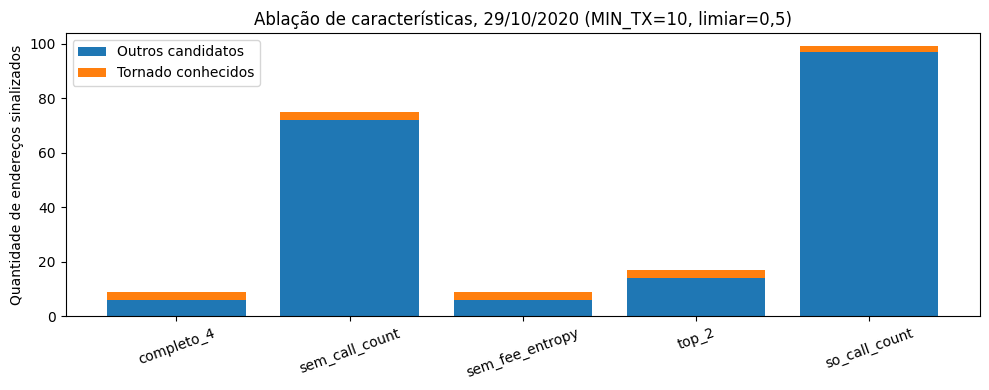

In [3]:
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(results.configuracao,results.outros_sinalizados,label='Outros candidatos')
ax.bar(results.configuracao,results.tornado_detectados,bottom=results.outros_sinalizados,label='Tornado conhecidos')
ax.set_ylabel('Quantidade de endereços sinalizados')
ax.set_title('Ablação de características, 29/10/2020 (MIN_TX=10, limiar=0,5)')
ax.legend(); ax.tick_params(axis='x',rotation=20);fig.tight_layout()
fig.savefig(RES/'ablacao_comparacao_20201029.png',dpi=180)
plt.show()

## 4. Análise de limiar e lista de candidatos
Os limiares abaixo são diagnósticos exploratórios, não uma otimização em conjunto de teste com rótulos completos.

In [4]:
lines=[]
for nome, score in score_by_config.items():
    for limiar in [0.5,0.6,0.7,0.8,0.9]:
        mask=score>limiar
        n_t=int(te.loc[mask,'tornado'].notna().sum())
        lines.append({'configuracao':nome,'limiar':limiar,'sinalizados':int(mask.sum()),
                      'tornado_detectados':n_t,'outros_sinalizados':int(mask.sum())-n_t})
sensitivity=pd.DataFrame(lines)
sensitivity.to_csv(RES/'ablacao_sensibilidade_20201029.csv',index=False)
display(sensitivity[sensitivity.configuracao=='completo_4'])

# Lista específica dos candidatos da configuração de referência para verificação no Etherscan
mask=score_by_config['completo_4']>LIMIAR
candidates=te.loc[mask,['recipient','n_tx','tornado']].copy()
candidates['prob_mixer']=score_by_config['completo_4'][mask]
candidates['etherscan']='https://etherscan.io/address/'+candidates['recipient'].astype(str)
candidates['rotulo_confirmado']='PENDENTE_VERIFICACAO'
candidates=candidates.sort_values('prob_mixer',ascending=False)
candidates.to_csv(RES/'ablacao_candidatos_a_validar.csv',index=False)
display(candidates)

,configuracao,limiar,sinalizados,tornado_detectados,outros_sinalizados
0,completo_4,0.5,9,3,6
1,completo_4,0.6,8,3,5
2,completo_4,0.7,8,3,5
3,completo_4,0.8,7,3,4
4,completo_4,0.9,3,0,3


,recipient,n_tx,tornado,prob_mixer,etherscan,rotulo_confirmado
86557,0x5e60fcca904753a31f9df7d7f6b7856b6ec27aa9,53,None,1.00,https://etherscan.io/address/0x5e60fcca904753a...,PENDENTE_VERIFICACAO
138954,0x98f1858c9740b9c5f2cd8abea67948873d38dc39,10,None,0.98,https://etherscan.io/address/0x98f1858c9740b9c...,PENDENTE_VERIFICACAO
200935,0xde7b3b2fe0e7b4925107615a5b199a4eb40d9ca9,52,None,0.91,https://etherscan.io/address/0xde7b3b2fe0e7b49...,PENDENTE_VERIFICACAO
17637,0x12d66f87a04a9e220743712ce6d9bb1b5616b8fc,73,0.1 ETH,0.87,https://etherscan.io/address/0x12d66f87a04a9e2...,PENDENTE_VERIFICACAO
66101,0x47ce0c6ed5b0ce3d3a51fdb1c52dc66a7c3c2936,55,1 ETH,0.87,https://etherscan.io/address/0x47ce0c6ed5b0ce3...,PENDENTE_VERIFICACAO
146385,0xa160cdab225685da1d56aa342ad8841c3b53f291,29,None,0.87,https://etherscan.io/address/0xa160cdab225685d...,PENDENTE_VERIFICACAO
131957,0x910cbd523d972eb0a6f4cae4618ad62622b39dbf,111,10 ETH,0.86,https://etherscan.io/address/0x910cbd523d972eb...,PENDENTE_VERIFICACAO
203271,0xe113d58a4cb4dbac8a0da608ed7232785c1f2c18,10,None,0.76,https://etherscan.io/address/0xe113d58a4cb4dba...,PENDENTE_VERIFICACAO
155862,0xabea9132b05a70803a4e85094fd0e1800777fbef,25,None,0.59,https://etherscan.io/address/0xabea9132b05a708...,PENDENTE_VERIFICACAO


## 5. Como defender os resultados
1. **Reprodução do conjunto de teste:** as contagens do Blockchair coincidem com o artigo, inclusive as 239 transações dos 3 contratos conhecidos.
2. **Implementação adaptada:** a coleta via Router aumenta o conjunto positivo; o filtro por transações e a discretização de entropia são decisões próprias, não especificadas pelo artigo.
3. **Ablação:** explique quais características melhoraram ou pioraram os resultados ao serem removidas, consultando a tabela produzida nesta execução.
4. **Limitação da validação:** 23 dias do mesmo contrato não equivalem a 23 mixers independentes; a validação cruzada pode parecer excelente mesmo com generalização limitada.
5. **Próximo experimento:** avaliar outro dia **não usado** para seleção de parâmetros e, idealmente, outros contratos com rótulos confirmados. Comparar conjuntos com a mesma unidade experimental.

**Importante:** não atribua resultados numéricos a este notebook até executar todas as células e verificar os arquivos CSV gravados.